# Import

In [53]:
import glob
import numpy as np
import matplotlib.pyplot as plt
import dbetto
import lh5
import pandas as pd
import pygeomhades
import pygeomtools
import yaml
from pygeomtools import write_pygeom
import pyg4ometry as pg4
from pyg4ometry import gdml
from pathlib import Path
from copy import deepcopy
from matplotlib.colors import LogNorm

from scipy.optimize import least_squares
from scipy.special import erf, erfc, xlogy
from scipy.stats import exponnorm

%matplotlib inline


In [2]:
import reboost
from reboost import hpge
from reboost.hpge import surface, psd
from reboost.shape import group
from reboost.math import functions
from reboost.math.stats import gaussian_sample
from reboost.utils import get_remage_detector_uids





In [3]:
from remage import remage_run



# functions

In [4]:
def find_matching_background_runs(db, detector, measure, campaign="c1"):
    configuration = db.hardware.configuration[detector][campaign]

    physics_runs = configuration[measure]
    background_runs = configuration["bkg"]

    matches = {}

    for run, data in sorted(physics_runs.items()):
        if not run.startswith("run"):
            continue

        card = data["daq_settings"]["flashcam"]["card_interface"]

        matching_bkg = [
            bkg_run
            for bkg_run, bkg_data in sorted(background_runs.items())
            if bkg_run.startswith("run")
            and bkg_data["daq_settings"]["flashcam"]["card_interface"] == card
        ]

        matches[run] = {
            "card_interface": card,
            "background_runs": matching_bkg,
        }

    return matches

In [5]:

def gaussian_bin_counts(edges, area, mu, sigma):
    z = (edges - mu) / (np.sqrt(2) * sigma)
    return area * 0.5 * np.diff(erf(z))


def left_tail_bin_counts(edges, area, mu, sigma, tau):
    cdf = exponnorm.sf(
        mu - edges,
        tau / sigma,
        loc=0,
        scale=sigma,
    )

    return area * np.maximum(np.diff(cdf), 0)


def step_primitive(x, mu, sigma):
    u = (x - mu) / (np.sqrt(2) * sigma)

    return 0.5 * (
        (x - mu) * erfc(u)
        - sigma * np.sqrt(2 / np.pi) * np.exp(-u**2)
    )


def am60_components(edges, parameters):
    (
        area, mu, sigma,
        tail_area, tau,
        background, step,
    ) = parameters

    peak = gaussian_bin_counts(edges, area, mu, sigma)
    tail = left_tail_bin_counts(
        edges, tail_area, mu, sigma, tau
    )

    continuum = (
        background * np.diff(edges)
        + step * np.diff(
            step_primitive(edges, mu, sigma)
        )
    )

    return {
        "gaussian": peak,
        "tail": tail,
        "continuum": continuum,
        "total": peak + tail + continuum,
    }


def am60_density(x, parameters):
    (
        area, mu, sigma,
        tail_area, tau,
        background, step,
    ) = parameters

    peak = (
        area / (np.sqrt(2 * np.pi) * sigma)
        * np.exp(-0.5 * ((x - mu) / sigma)**2)
    )

    tail = tail_area * exponnorm.pdf(
        mu - x,
        tau / sigma,
        loc=0,
        scale=sigma,
    )

    continuum = (
        background
        + step * 0.5 * erfc(
            (x - mu) / (np.sqrt(2) * sigma)
        )
    )

    return {
        "gaussian": peak,
        "tail": tail,
        "continuum": continuum,
        "total": peak + tail + continuum,
    }


def poisson_residuals(parameters, edges, counts):
    expected = np.maximum(
        am60_components(edges, parameters)["total"],
        1e-12,
    )

    deviance = 2 * (
        expected - counts
        + xlogy(counts, counts / expected)
    )

    return (
        np.sign(expected - counts)
        * np.sqrt(np.maximum(deviance, 0))
    )



In [6]:


def am100_components(edges, parameters):
    (
        N1, mu1,
        N2, mu2,
        N3, mu3,
        sigma,
        S1, S2,
        B,
    ) = parameters

    edges = np.asarray(edges, dtype=float)
    widths = np.diff(edges)

    def gaussian_counts(N, mu):
        return N * np.diff(ndtr((edges - mu) / sigma))

    def step_counts(S, mu):
        # Densità dello step: S * Phi((mu - E) / sigma)
        # Primitiva rispetto all'energia.
        z = (mu - edges) / sigma
        phi = np.exp(-0.5 * z**2) / np.sqrt(2 * np.pi)

        primitive = (
            (edges - mu) * ndtr(z)
            - sigma * phi
        )

        return S * np.maximum(np.diff(primitive), 0.0)

    g1 = gaussian_counts(N1, mu1)
    g2 = gaussian_counts(N2, mu2)
    g3 = gaussian_counts(N3, mu3)

    step1 = step_counts(S1, mu1)
    step2 = step_counts(S2, mu3)

    background = B * widths

    return {
        "gaussian_99": g1,
        "gaussian_101": g2,
        "gaussian_103": g3,
        "step_99": step1,
        "step_103": step2,
        "background": background,
        "total": g1 + g2 + g3 + step1 + step2 + background,
    }


def poisson_residuals_am100(parameters, edges, y):
    expected = am100_components(edges, parameters)["total"]
    expected = np.maximum(expected, np.finfo(float).tiny)

    # Residui della devianza di Poisson, inclusi i bin vuoti.
    deviance = expected - y
    positive = y > 0

    deviance[positive] += y[positive] * (
        np.log(y[positive]) - np.log(expected[positive])
    )

    return np.sign(y - expected) * np.sqrt(
        2.0 * np.maximum(deviance, 0.0)
    )


def fit_am_100(counts, bins, fit_range=(96.0, 106.0)):
    counts = np.asarray(counts, dtype=float)
    bins = np.asarray(bins, dtype=float)

    if counts.ndim != 1 or bins.ndim != 1:
        raise ValueError("counts e bins devono essere 1D.")

    if counts.size == 0 or bins.size != counts.size + 1:
        raise ValueError("Dimensioni istogramma incompatibili.")

    if not np.isfinite(counts).all() or np.any(counts < 0):
        raise ValueError("Conteggi non validi.")

    if not np.isfinite(bins).all() or np.any(np.diff(bins) <= 0):
        raise ValueError("Bordi non validi.")

    xmin, xmax = fit_range

    if not np.isfinite([xmin, xmax]).all() or xmin >= xmax:
        raise ValueError("Finestra di fit non valida.")

    indices = np.flatnonzero(
        (bins[:-1] >= xmin)
        & (bins[1:] <= xmax)
    )

    # 3 aree, 3 centroidi, 1 sigma, 2 step, 1 fondo.
    n_parameters = 10

    if indices.size <= n_parameters:
        raise ValueError("Troppi pochi bin nella finestra di fit.")

    first = indices[0]
    last = indices[-1] + 1

    edges = bins[first:last + 1]
    y = counts[first:last]

    if y.sum() <= 0:
        raise ValueError("Nessun conteggio nella finestra di fit.")

    if edges[0] >= 99.0 or edges[-1] <= 103.0:
        raise ValueError("La finestra deve includere tutti e tre i picchi.")

    widths = np.diff(edges)
    centers = (edges[:-1] + edges[1:]) / 2
    density = y / widths

    background = max(
        float(np.percentile(density, 10)),
        1e-3,
    )

    sigma_guess = 0.4

    def area_guess(mu):
        height = max(
            float(density[np.argmin(np.abs(centers - mu))])
            - background,
            1.0,
        )
        return height * np.sqrt(2 * np.pi) * sigma_guess

    # Ordine: N1, mu1, N2, mu2, N3, mu3, sigma, S1, S2, B.
    p0 = [
        area_guess(99.0), 99.0,
        area_guess(101.1), 101.1,
        area_guess(103.0), 103.0,
        sigma_guess,
        background * 0.5,
        background * 0.5,
        background,
    ]

    lower = [
        0.0, 98.5,
        0.0, 100.6,
        0.0, 102.5,
        0.05,
        0.0, 0.0,
        0.0,
    ]

    upper = [
        np.inf, 99.5,
        np.inf, 101.6,
        np.inf, 103.5,
        1.2,
        np.inf, np.inf,
        np.inf,
    ]

    fit = least_squares(
        poisson_residuals_am100,
        p0,
        bounds=(lower, upper),
        args=(edges, y),
        x_scale="jac",
        max_nfev=20000,
    )

    if not fit.success:
        raise RuntimeError(f"Fit fallito: {fit.message}")

    rank = np.linalg.matrix_rank(fit.jac)
    full_rank = rank == n_parameters

    covariance = (
        np.linalg.pinv(fit.jac.T @ fit.jac)
        if full_rank
        else np.full((n_parameters, n_parameters), np.nan)
    )

    errors = np.sqrt(
        np.maximum(np.diag(covariance), 0.0)
    )

    peak_indices = [0, 2, 4]
    areas = fit.x[peak_indices].copy()

    if not np.isfinite(areas).all() or np.any(areas <= 0):
        raise ValueError("Aree dei picchi non valide.")

    return {
        "parameter_names": [
            "N1", "mu1",
            "N2", "mu2",
            "N3", "mu3",
            "sigma",
            "S1", "S2",
            "B",
        ],
        "parameters": fit.x,
        "errors": errors,
        "covariance": covariance,
        "area_peak": areas,
        "area_peak_errors": errors[peak_indices],
        "mu": fit.x[[1, 3, 5]],
        "mu_errors": errors[[1, 3, 5]],
        "fwhm": 2.35482 * fit.x[6],
        "fwhm_error": 2.35482 * errors[6],
        "edges": edges,
        "counts": y,
        "components": am100_components(edges, fit.x),
        "residuals": fit.fun,
        "deviance": float(np.sum(fit.fun**2)),
        "ndof": y.size - n_parameters,
        "full_rank": full_rank,
        "at_bounds": bool(np.any(fit.active_mask != 0)),
        "active_mask": fit.active_mask,
        "nfev": fit.nfev,
        "message": fit.message,
    }

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import ndtr


def am100_density(x, parameters):
    (
        N1, mu1,
        N2, mu2,
        N3, mu3,
        sigma,
        S1, S2,
        B,
    ) = parameters

    x = np.asarray(x, dtype=float)

    def gaussian(N, mu):
        return (
            N / (np.sqrt(2 * np.pi) * sigma)
            * np.exp(-0.5 * ((x - mu) / sigma)**2)
        )

    g1 = gaussian(N1, mu1)
    g2 = gaussian(N2, mu2)
    g3 = gaussian(N3, mu3)

    step1 = S1 * ndtr((mu1 - x) / sigma)
    step2 = S2 * ndtr((mu3 - x) / sigma)
    background = np.full_like(x, B)

    return {
        "gaussian_99": g1,
        "gaussian_101": g2,
        "gaussian_103": g3,
        "step_99": step1,
        "step_103": step2,
        "background": background,
        "total": g1 + g2 + g3 + step1 + step2 + background,
    }


# ============================================================
# FIT FIGURE: EXACTLY (5, 3)
# ============================================================

def plot_am100_fit(result, detector, run, meta, dpi=300):
    fig, (ax, ax_res) = plt.subplots(
        2, 1,
        figsize=(5, 3),
        sharex=True,
        height_ratios=[3, 1],
        layout="constrained",
        dpi=dpi,
    )

    edges = result["edges"]
    centers = (edges[:-1] + edges[1:]) / 2
    widths = np.diff(edges)
    width = widths[0]

    if not np.allclose(widths, width):
        plt.close(fig)
        raise ValueError("Questo plot richiede bin di larghezza uniforme.")

    x = np.linspace(edges[0], edges[-1], 3000)
    smooth = am100_density(x, result["parameters"])

    ax.stairs(
        result["counts"],
        edges,
        color="navy",
        linewidth=0.8,
        label="Data",
    )

    for key, label, color, linestyle in [
        ("total", "Total", "darkorange", "-"),
        ("gaussian_99", "Gaussian 99 keV", "crimson", "--"),
        ("gaussian_101", "Gaussian 101.1 keV", "deepskyblue", "--"),
        ("gaussian_103", "Gaussian 103 keV", "green", "--"),
        ("step_99", "Step 99 keV", "purple", "--"),
        ("step_103", "Step 103 keV", "brown", "--"),
        ("background", "Background", "gray", "--"),
    ]:
        curve = smooth[key] * width

        ax.plot(
            x,
            np.where(curve > 0, curve, np.nan),
            color=color,
            linestyle=linestyle,
            linewidth=0.9,
            label=label,
        )

    ax.set_yscale("log")

    positive = result["counts"][result["counts"] > 0]
    ymax = max(
        result["counts"].max(),
        smooth["total"].max() * width,
    )

    #ax.set_ylim(
    #    max(0.1, min(100.0, positive.min() * 0.5)),
   #     ymax * 2,
   # )

    ax.set_ylim(
        0.01, 2e3
    )

    p = result["parameters"]
    errors = result["errors"]

    text = (
        rf"$A_1={p[0]:.0f}\pm{errors[0]:.0f}$ counts" "\n"
        rf"$\mu_1={p[1]:.4f}\pm{errors[1]:.4f}$ keV" "\n"
        rf"$A_2={p[2]:.0f}\pm{errors[2]:.0f}$ counts" "\n"
        rf"$\mu_2={p[3]:.4f}\pm{errors[3]:.4f}$ keV" "\n"
        rf"$A_3={p[4]:.0f}\pm{errors[4]:.0f}$ counts" "\n"
        rf"$\mu_3={p[5]:.4f}\pm{errors[5]:.4f}$ keV" "\n"
        rf"$\sigma={p[6]:.4f}\pm{errors[6]:.4f}$ keV" "\n"
        rf"$S_1={p[7]:.1f}\pm{errors[7]:.1f}$ counts/keV" "\n"
        rf"$S_2={p[8]:.1f}\pm{errors[8]:.1f}$ counts/keV" "\n"
        rf"$B={p[9]:.1f}\pm{errors[9]:.1f}$ counts/keV" "\n"
        f"FWHM={result['fwhm']:.4f}"
        f" ± {result['fwhm_error']:.4f} keV\n"
        f"D/ndof={result['deviance']:.1f}/{result['ndof']}"
    )

    ax.text(
        0.98, 0.97,
        text,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=5,
        color="navy",
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.85,
            "pad": 2,
        },
    )

    pos = meta["source_position"]

    ax.set_title(
        f"{detector}/{run} | "
        f"r={float(pos['r_in_mm']):g}, "
        f"z={float(pos['z_in_mm']):g} mm, "
        f"φ={float(pos['phi_in_deg']):g}° | "
        f"t={float(meta['run_live_time_in_s']) / 3600:g} h",
        fontsize=7,
    )

    ax.set_ylabel(f"Counts / {width:g} keV", fontsize=7)
    ax.legend(fontsize=5.5, loc="upper left")

    ax_res.axhline(
        0,
        color="gray",
        linestyle="--",
        linewidth=0.6,
    )

    ax_res.plot(
        centers,
        result["residuals"],
        ".",
        color="navy",
        markersize=2,
    )

    ax_res.set_ylabel("Deviance\nresidual", fontsize=6)
    ax_res.set_xlabel("Energy (keV)", fontsize=7)
    ax_res.set_xlim(edges[0], edges[-1])

    for axis in (ax, ax_res):
        axis.tick_params(labelsize=6)

    return fig



In [7]:

def am60_components(edges, parameters):
    area, mu, sigma, tail_area, tau, S = parameters

    edges = np.asarray(edges, dtype=float)

    gaussian = area * np.maximum(
        np.diff(ndtr((edges - mu) / sigma)),
        0.0,
    )

    distribution = exponnorm(
        tau / sigma,
        loc=mu,
        scale=sigma,
    )

    cdf = distribution.cdf(edges)
    sf = distribution.sf(edges)

    probability = np.where(
        cdf[:-1] > 0.5,
        sf[:-1] - sf[1:],
        cdf[1:] - cdf[:-1],
    )

    tail = tail_area * np.maximum(probability, 0.0)

    z = (mu - edges) / sigma
    phi = np.exp(-0.5 * z**2) / np.sqrt(2 * np.pi)

    primitive = (
        (edges - mu) * ndtr(z)
        - sigma * phi
    )

    step = S * np.maximum(
        np.diff(primitive), 0.0
    )

    return {
        "gaussian": gaussian,
        "tail": tail,
        "step": step,
        "total": gaussian + tail + step,
    }


def am60_density(x, parameters):
    area, mu, sigma, tail_area, tau, S = parameters

    x = np.asarray(x, dtype=float)

    gaussian = (
        area / (np.sqrt(2 * np.pi) * sigma)
        * np.exp(-0.5 * ((x - mu) / sigma)**2)
    )

    tail = tail_area * exponnorm.pdf(
        x,
        tau / sigma,
        loc=mu,
        scale=sigma,
    )

    step = S * ndtr((mu - x) / sigma)

    return {
        "gaussian": gaussian,
        "tail": tail,
        "step": step,
        "total": gaussian + tail + step,
    }
    
def am60_density(x, parameters):
    area, mu, sigma, tail_area, tau, S = parameters

    x = np.asarray(x, dtype=float)

    gaussian = (
        area / (np.sqrt(2 * np.pi) * sigma)
        * np.exp(-0.5 * ((x - mu) / sigma)**2)
    )

    tail = tail_area * exponnorm.pdf(
        x,
        tau / sigma,
        loc=mu,
        scale=sigma,
    )

    step = S * ndtr((mu - x) / sigma)

    return {
        "gaussian": gaussian,
        "tail": tail,
        "step": step,
        "total": gaussian + tail + step,
    }


# ============================================================
# POISSON DEVIANCE RESIDUALS
# ============================================================

def poisson_residuals(parameters, edges, counts):
    expected = np.maximum(
        am60_components(edges, parameters)["total"],
        np.finfo(float).tiny,
    )

    half_deviance = expected.copy()
    positive = counts > 0

    observed = counts[positive]
    predicted = expected[positive]

    delta = (predicted - observed) / observed

    near = np.abs(delta) < 0.01
    terms = np.empty_like(delta)

    # Stable expansion near predicted == observed.
    d = delta[near]

    terms[near] = d**2 * (
        0.5 - d / 3 + d**2 / 4
        - d**3 / 5 + d**4 / 6
    )

    terms[~near] = (
        delta[~near]
        + np.log(observed[~near])
        - np.log(predicted[~near])
    )

    half_deviance[positive] = observed * terms

    # Positive residual: data exceed the model.
    return np.sign(counts - expected) * np.sqrt(
        2.0 * np.maximum(half_deviance, 0.0)
    )


# ============================================================
# FIT CALIBRATED RAW COUNTS
# ============================================================

def fit_am60(counts, bins, fit_range=(57, 70)):
    counts = np.asarray(counts, dtype=float)
    bins = np.asarray(bins, dtype=float)

    if counts.ndim != 1 or bins.ndim != 1:
        raise ValueError("counts e bins devono essere 1D.")

    if counts.size == 0 or bins.size != counts.size + 1:
        raise ValueError("Dimensioni istogramma incompatibili.")

    if not np.isfinite(counts).all() or np.any(counts < 0):
        raise ValueError("Conteggi non validi.")

    if (
        not np.isfinite(bins).all()
        or np.any(np.diff(bins) <= 0)
    ):
        raise ValueError("Bordi non validi.")

    xmin, xmax = fit_range

    if not np.isfinite([xmin, xmax]).all() or xmin >= xmax:
        raise ValueError("Finestra di fit non valida.")

    indices = np.flatnonzero(
        (bins[:-1] >= xmin)
        & (bins[1:] <= xmax)
    )

    n_parameters = len(PARAMETER_NAMES)

    if indices.size <= n_parameters:
        raise ValueError(
            "Troppi pochi bin per un fit con 6 parametri."
        )

    first = indices[0]
    last = indices[-1] + 1

    edges = bins[first:last + 1]
    y = counts[first:last]

    if y.sum() <= 0:
        raise ValueError(
            "Nessun conteggio nella finestra di fit."
        )

    if not (edges[0] < 59.54 < edges[-1]):
        raise ValueError(
            "La finestra deve includere il picco a 59.54 keV."
        )

    centers = (edges[:-1] + edges[1:]) / 2
    density = y / np.diff(edges)

    mu_guess = 59.54
    sigma_guess = 0.3

    # Estimate the step plateau below the peak.
    low_energy = centers < 58.5

    step_guess = max(
        float(np.percentile(density[low_energy], 20))
        if np.any(low_energy)
        else float(np.percentile(density, 20)),
        1e-3,
    )

    index = np.argmin(np.abs(centers - mu_guess))

    height = max(
        float(density[index]) - 0.5 * step_guess,
        1.0,
    )

    area_guess = (
        height * np.sqrt(2 * np.pi) * sigma_guess
    )

    # area_peak, mu, sigma, area_tail, tau, step
    p0 = [
        area_guess,
        mu_guess,
        sigma_guess,
        area_guess * 0.02,
        1.0,
        step_guess,
    ]

    lower = [
        0.0,
        58.8,
        0.05,
        0.0,
        0.05,
        0.0,
    ]

    upper = [
        np.inf,
        60.3,
        1.2,
        np.inf,
        10.0,
        np.inf,
    ]

    fit = least_squares(
        poisson_residuals,
        p0,
        bounds=(lower, upper),
        args=(edges, y),
        x_scale="jac",
        max_nfev=20000,
    )

    if not fit.success:
        raise RuntimeError(f"Fit fallito: {fit.message}")

    # Column scaling reduces sensitivity of the rank check
    # to the very different parameter units and magnitudes.
    column_norms = np.linalg.norm(fit.jac, axis=0)
    safe_norms = np.where(column_norms > 0, column_norms, 1.0)
    scaled_jacobian = fit.jac / safe_norms

    full_rank = (
        np.linalg.matrix_rank(scaled_jacobian)
        == n_parameters
    )

    if full_rank:
        _, singular_values, vt = np.linalg.svd(
            scaled_jacobian,
            full_matrices=False,
        )

        scaled_covariance = (
            vt.T / singular_values**2
        ) @ vt

        covariance = (
            scaled_covariance
            / safe_norms[:, None]
            / safe_norms[None, :]
        )

    else:
        covariance = np.full(
            (n_parameters, n_parameters),
            np.nan,
        )

    errors = np.sqrt(
        np.maximum(np.diag(covariance), 0.0)
    )

    if not np.isfinite(fit.x).all() or fit.x[0] <= 0:
        raise ValueError(
            "Parametri o area gaussiana non validi."
        )

    result = {
        "parameter_names": PARAMETER_NAMES.copy(),
        "parameters": fit.x,
        "errors": errors,
        "covariance": covariance,

        "area_peak": fit.x[0],
        "area_peak_error": errors[0],

        "mu": fit.x[1],
        "mu_error": errors[1],

        "sigma": fit.x[2],
        "sigma_error": errors[2],

        "area_tail": fit.x[3],
        "area_tail_error": errors[3],

        "tau": fit.x[4],
        "tau_error": errors[4],

        "step": fit.x[5],
        "step_error": errors[5],

        # FWHM of the Gaussian component only.
        "fwhm": 2.35482 * fit.x[2],
        "fwhm_error": 2.35482 * errors[2],

        "edges": edges,
        "counts": y,
        "components": am60_components(edges, fit.x),
        "residuals": fit.fun,
        "deviance": float(np.sum(fit.fun**2)),
        "ndof": y.size - n_parameters,

        "full_rank": full_rank,
        "at_bounds": bool(np.any(fit.active_mask != 0)),
        "active_mask": fit.active_mask,
        "nfev": fit.nfev,
        "message": fit.message,
    }

    for name, value, error in zip(
        PARAMETER_NAMES,
        fit.x,
        errors,
    ):
        print(f"{name} = {value:.6g} ± {error:.3g}")

    print(
        f"FWHM gaussiana = {result['fwhm']:.5f}"
        f" ± {result['fwhm_error']:.3g} keV\n"
        f"Deviance / ndof = "
        f"{result['deviance']:.2f}/{result['ndof']}"
    )

    if result["at_bounds"]:
        names_at_bounds = [
            name
            for name, active in zip(
                PARAMETER_NAMES,
                fit.active_mask,
            )
            if active != 0
        ]

        print(
            "CHECK FIT: parametri al limite: "
            + ", ".join(names_at_bounds)
        )

    if not full_rank:
        print("CHECK FIT: incertezze non identificabili.")

    return result


# ============================================================
# FIT FIGURE: (5, 3)
# ============================================================

def plot_am60_fit(result, detector, run, meta, dpi=300):
    edges = result["edges"]
    widths = np.diff(edges)
    centers = (edges[:-1] + edges[1:]) / 2

    uniform = np.allclose(widths, widths[0])

    if uniform:
        values = result["counts"]
        curve_scale = widths[0]
        ylabel = f"Counts / {widths[0]:g} keV"
    else:
        values = result["counts"] / widths
        curve_scale = 1.0
        ylabel = "Counts / keV"

    x = np.linspace(
        edges[0], edges[-1], 3000
    )

    smooth = am60_density(
        x, result["parameters"]
    )

    fig, (ax, ax_res) = plt.subplots(
        2, 1,
        figsize=(5, 3),
        sharex=True,
        height_ratios=[3, 1],
        layout="constrained",
        dpi=dpi,
    )

    ax.stairs(
        values,
        edges,
        color="navy",
        linewidth=0.8,
        label="Data",
    )

    for key, label, color, linestyle in [
        ("total", "Total fit", "darkorange", "-"),
        ("gaussian", "Gaussian", "crimson", "--"),
        ("tail", "Right tail", "deepskyblue", "--"),
        ("step", "Step", "purple", "--"),
    ]:
        curve = smooth[key] * curve_scale

        ax.plot(
            x,
            np.where(curve > 0, curve, np.nan),
            color=color,
            linestyle=linestyle,
            linewidth=0.9,
            label=label,
        )

    ax.set_yscale("log")

    positive = values[values > 0]

    ax.set_ylim(
        min(0.5, positive.min() / 2),
        max(
            values.max(),
            smooth["total"].max() * curve_scale,
        ) * 2,
    )

    labels = [
        "A_G", "mu", "sigma",
        "A_right", "tau_right", "S",
    ]

    units = [
        "counts", "keV", "keV",
        "counts", "keV", "counts/keV",
    ]

    lines = [
        f"{label}={value:.4g} ± {error:.2g} {unit}"
        for label, value, error, unit in zip(
            labels,
            result["parameters"],
            result["errors"],
            units,
        )
    ]

    lines += [
        f"FWHM={result['fwhm']:.4f}"
        f" ± {result['fwhm_error']:.3g} keV",
        f"D/ndof={result['deviance']:.1f}/{result['ndof']}",
    ]

    ax.text(
        0.98, 0.97,
        "\n".join(lines),
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=5,
        color="navy",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.85,
            pad=2,
        ),
    )

    pos = meta["source_position"]

    ax.set_title(
        f"{detector}/{run} | "
        f"r={float(pos['r_in_mm']):g}, "
        f"z={float(pos['z_in_mm']):g} mm, "
        f"φ={float(pos['phi_in_deg']):g}° | "
        f"t={float(meta['run_live_time_in_s']) / 3600:g} h",
        fontsize=7,
    )

    ax.set_ylabel(ylabel, fontsize=7)
    ax.legend(
        fontsize=5.5,
        loc="upper left",
        frameon=False,
    )

    ax_res.axhline(
        0,
        color="gray",
        linestyle="--",
        linewidth=0.6,
    )

    ax_res.plot(
        centers,
        result["residuals"],
        ".",
        color="navy",
        markersize=2,
    )

    ax_res.set_ylabel(
        "Deviance\nresidual",
        fontsize=6,
    )

    ax_res.set_xlabel(
        "Energy (keV)",
        fontsize=7,
    )

    ax_res.set_xlim(
        edges[0], edges[-1]
    )

    for axis in (ax, ax_res):
        axis.tick_params(labelsize=6)

    return fig



# Metadata HADES

In [8]:
detector = "V03421A"
version = "v1.2.1"

#detector = "V08682B"
#version = "v1.1.0"

measure = "am_HS1_top_dlt"
run = 3
campaign = "c1"



In [9]:
run_key = f"run{int(run):04d}"   # run0002: metadati
run_tag = f"r{int(run):03d}"     # r002: file LH5

In [10]:
metadata_path = "/global/u2/r/ritaferi/HADES_DATA/hades-metadata"
db = dbetto.TextDB(metadata_path)


In [11]:
db_data = db.hardware.configuration[detector]["c1"][measure][run_key]

In [12]:
#db_bkg = db.hardware.configuration[detector]["c1"]["bkg"][f'run0001']

# data and background

In [13]:
import glob
#measure = 'th_HS2_top_psa'

def find_same_card_runs(
    db,
    detector,
    version=version,
    measure=measure,
    campaign=campaign,
):
    base = (
        "/global/cfs/cdirs/m2676/data/teststands/hades/"
        f"prodenv/ref/{version}/generated/tier/hit/"
        f"{detector}/{campaign}"
    )

    print(base)

    def get_available_runs(measurement):
        try:
            config = (
                db.hardware.configuration[detector]
                [campaign][measurement]
            )
        except (KeyError, FileNotFoundError):
            print(
                f"{detector}: metadata missing for "
                f"{campaign}/{measurement}."
            )
            return {}

        available = {}

        print(f"\n--- {detector} / {measurement}: all cards ---")

        for run in sorted(config.keys()):
            if not (
                run.startswith("run")
                and run[3:].isdigit()
            ):
                continue

            try:
                meta = config[run]

                card = (
                    meta["daq_settings"]["flashcam"]
                    ["card_interface"]
                )

                if card is None or card == "":
                    raise ValueError("Empty card_interface.")

                # Print even if physics files are unavailable.
                print(
                    f"{detector}/{measurement}/{run} | "
                    f"card_interface: {card}"
                )

                # run0001 -> r001
                run_tag = f"r{int(run[3:]):03d}"

                pattern = (
                    f"{base}/{measurement}/"
                    f"char_data-{detector}-{measurement}-"
                    f"{run_tag}-*-tier_hit.lh5"
                )

                files = sorted(glob.glob(pattern))

                if not files:
                    print(
                        f"  No physics files found: "
                        f"{measurement}/{run} excluded from pairing."
                    )
                    continue

                available[run] = {
                    "card_interface": card,
                    "metadata": meta,
                    "files": files,
                }

            except (
                KeyError,
                FileNotFoundError,
                TypeError,
                ValueError,
            ) as exc:
                print(
                    f"Skipping {detector}/{measurement}/{run}: {exc}"
                )

        return available

    measurement_runs = get_available_runs(measure)
    background_runs = get_available_runs("bkg")

    pairs = []

    print(f"\n--- {detector}: matching pairs ---")

    for run_measure, info_measure in measurement_runs.items():
        for run_background, info_background in background_runs.items():
            if (
                info_measure["card_interface"]
                != info_background["card_interface"]
            ):
                continue

            pairs.append({
                "detector": detector,
                "measurement_run": run_measure,
                "background_run": run_background,
                "card_interface": info_measure["card_interface"],
                "measurement_files": info_measure["files"],
                "background_files": info_background["files"],
                "measurement_metadata": info_measure["metadata"],
                "background_metadata": info_background["metadata"],
            })

            print(
                f"{measure}/{run_measure} ↔ bkg/{run_background}\n"
                f"  Card: {info_measure['card_interface']}\n"
                f"  Measurement files: {len(info_measure['files'])}\n"
                f"  Background files: {len(info_background['files'])}"
            )

    if not pairs:
        print(
            "No pairs with matching card_interface "
            "and available physics files."
        )

    return pairs

In [14]:
pairs = find_same_card_runs(
    db,
    detector=detector,
    version=version,
    measure=measure,
    campaign=campaign,
)

# File della prima coppia compatibile.
if pairs:
    file_names = pairs[0]["measurement_files"]
    file_names_bkg = pairs[0]["background_files"]

/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref/v1.2.1/generated/tier/hit/V03421A/c1

--- V03421A / am_HS1_top_dlt: all cards ---
V03421A/am_HS1_top_dlt/run0001 | card_interface: efb3
V03421A/am_HS1_top_dlt/run0002 | card_interface: efb3
V03421A/am_HS1_top_dlt/run0003 | card_interface: efb3

--- V03421A / bkg: all cards ---
V03421A/bkg/run0001 | card_interface: efb1
V03421A/bkg/run0002 | card_interface: efb1
V03421A/bkg/run0003 | card_interface: efb3

--- V03421A: matching pairs ---
am_HS1_top_dlt/run0001 ↔ bkg/run0003
  Card: efb3
  Measurement files: 30
  Background files: 42
am_HS1_top_dlt/run0002 ↔ bkg/run0003
  Card: efb3
  Measurement files: 30
  Background files: 42
am_HS1_top_dlt/run0003 ↔ bkg/run0003
  Card: efb3
  Measurement files: 30
  Background files: 42


In [15]:
from collections.abc import Mapping
from pprint import pformat


def flatten_metadata(obj, prefix=""):
    result = {}

    if isinstance(obj, Mapping):
        for key, value in obj.items():
            path = f"{prefix}.{key}" if prefix else str(key)
            result.update(flatten_metadata(value, path))
    else:
        result[prefix] = obj

    return result


config = db.hardware.configuration[detector][campaign]["bkg"]

metadata = {
    run: flatten_metadata(config[run])
    for run in ["run0001", "run0002"]#, "run0003"]
}

fields = sorted({
    field
    for values in metadata.values()
    for field in values
})

for field in fields:
    values = {
        run: pformat(meta.get(field, "<missing>"))
        for run, meta in metadata.items()
    }

    if len(set(values.values())) > 1:
        print(f"\n{field}")

        for run, value in values.items():
            print(f"  {run}: {value}")


elog
  run0001: 'https://elog.legend-exp.org/HADES/369'
  run0002: 'https://elog.legend-exp.org/HADES/382'

high_voltage_in_V
  run0001: 3500
  run0002: 2600

run
  run0001: 'run0001'
  run0002: 'run0002'

run_start_time
  run0001: '240313T142230'
  run0002: '240319T152205'

shifter
  run0001: 'Slava'
  run0002: 'Mariia'


# Data and plot

In [16]:
bkg_tak = '3'
background_run_tag = f'r00{bkg_tak}'
# qui devo mttere il background che ha la stessa card interface perche rappresenta ka misura di static tble aassoociata. in questo caso abbiamo lo scanning table

In [17]:
run_tag

'r003'

In [18]:
file_pattern = (
    f"/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref/"
    f"{version}/generated/tier/hit/{detector}/{campaign}/{measure}/"
    f"char_data-{detector}-{measure}-{run_tag}-*.lh5"
)


file_background = (
    f"/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref/"
    f"{version}/generated/tier/hit/{detector}/{campaign}/bkg/"
    f"char_data-{detector}-bkg-{background_run_tag}-*-tier_hit.lh5"
)




In [19]:
file_names = sorted(glob.glob(file_pattern))
file_names_bkg = sorted(glob.glob(file_background))


In [20]:
if not file_names:
    raise FileNotFoundError(
        f"Nessun file trovato per {detector}, {measure}, {run_key}:\n"
        f"{file_pattern}"
    )

print(f"{run_key}: {len(file_names)} file trovati")




if not file_names_bkg:
    raise FileNotFoundError(file_background)
print(f"File background trovati: {len(file_names_bkg)}")

run0003: 30 file trovati
File background trovati: 42


In [21]:
background_run_tag

'r003'

In [22]:
emin = 0
emax = 7000
nbins = 70000
bins = np.linspace(emin, emax, nbins + 1)

force_rebuild = False

background_run_key =background_run_tag

spectrum_dir = (
    Path("raw_energy_spectrum")
    / version
    / campaign
    / detector
)

spectrum_dir.mkdir(parents=True, exist_ok=True)

spectrum_path = spectrum_dir / (
    f"{detector}_{measure}_{run_key}_spectrum.npz"
)

background_path = spectrum_dir / (
    f"{detector}_bkg_{background_run_key}_spectrum.npz"
)

# Stessi bordi per misura e background.
bins = np.linspace(emin, emax, nbins + 1)


# ============================================================
# BACKGROUND FILES
# ============================================================

file_background = (
    f"/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref/"
    f"{version}/generated/tier/hit/{detector}/{campaign}/bkg/"
    f"char_data-{detector}-bkg-{background_run_tag}-*-tier_hit.lh5"
)

file_names_bkg = sorted(glob.glob(file_background))




def load_or_build_spectrum(
    path,
    files,
    bins,
    force_rebuild=False,
):
    path = Path(path)
    bins = np.asarray(bins, dtype=float)

    if (
        bins.ndim != 1
        or bins.size < 2
        or not np.isfinite(bins).all()
        or np.any(np.diff(bins) <= 0)
    ):
        raise ValueError("Bordi dell'istogramma non validi.")

    if path.exists() and not force_rebuild:
        print(f"Carico: {path}", flush=True)

        with np.load(path, allow_pickle=False) as spectrum:
            required = {"counts", "counts_clean", "bins"}

            if required.issubset(spectrum.files):
                counts = np.asarray(spectrum["counts"]).copy()
                counts_clean = np.asarray(
                    spectrum["counts_clean"]
                ).copy()
                saved_bins = np.asarray(spectrum["bins"]).copy()

                valid = (
                    saved_bins.shape == bins.shape
                    and np.allclose(
                        saved_bins, bins, rtol=0, atol=1e-8
                    )
                    and counts.shape == (bins.size - 1,)
                    and counts_clean.shape == counts.shape
                    and np.isfinite(counts).all()
                    and np.isfinite(counts_clean).all()
                    and np.all(counts >= 0)
                    and np.all(counts_clean >= 0)
                    and np.all(counts_clean <= counts)
                )

                if valid:
                    return counts, counts_clean

                print("Cache incompatibile: rigenero.", flush=True)

            else:
                print(
                    "Cache senza counts_clean: rigenero.",
                    flush=True,
                )

    if len(files) == 0:
        raise FileNotFoundError(
            f"Nessun file LH5 disponibile per creare {path}"
        )

    counts = np.zeros(bins.size - 1, dtype=np.int64)
    counts_clean = np.zeros_like(counts)

    total_events = 0
    selected_events = 0

    for index, filename in enumerate(files, start=1):
        print(
            f"File {index}/{len(files)}: {Path(filename).name}",
            flush=True,
        )

        # Energia e flag devono provenire dallo STESSO file.
        hit = lh5.read(
            "hit",
            str(filename),
        )

        energy = np.asarray(
            hit["cuspEmax_ctc_cal"].nda
        )

        is_discharge = np.asarray(
            hit["is_discharge"].nda,
            dtype=bool,
        )

        is_positive = np.asarray(
            hit["is_positive_polarity_candidate"].nda,
            dtype=bool,
        )

        if (
            energy.ndim != 1
            or is_discharge.shape != energy.shape
            or is_positive.shape != energy.shape
        ):
            raise ValueError(
                f"Energia e flag incompatibili in {filename}: "
                f"energy={energy.shape}, "
                f"discharge={is_discharge.shape}, "
                f"positive={is_positive.shape}"
            )

        finite = np.isfinite(energy)

        mask = (
            finite
            & (~is_discharge)
            & is_positive
        )

        counts += np.histogram(
            energy[finite],
            bins=bins,
        )[0]

        counts_clean += np.histogram(
            energy[mask],
            bins=bins,
        )[0]

        total_events += energy.size
        selected_events += np.count_nonzero(mask)

        del hit, energy, is_discharge, is_positive, finite, mask

    path.parent.mkdir(parents=True, exist_ok=True)

    np.savez_compressed(
        path,
        counts=counts,
        counts_clean=counts_clean,
        bins=bins,
    )

    print(
        f"Salvato: {path}\n"
        f"Eventi totali: {total_events:,}\n"
        f"Eventi finiti che passano QC: {selected_events:,}",
        flush=True,
    )

    return counts, counts_clean

In [23]:
counts_data, counts_clean = load_or_build_spectrum(
    spectrum_path,
    file_names,
    bins,
    force_rebuild,
)

counts_bkg_noQC, counts_clean_bkg = load_or_build_spectrum(
    background_path,
    file_names_bkg,
    bins,
    force_rebuild,
)

Carico: raw_energy_spectrum/v1.2.1/c1/V03421A/V03421A_am_HS1_top_dlt_run0003_spectrum.npz
Carico: raw_energy_spectrum/v1.2.1/c1/V03421A/V03421A_bkg_r003_spectrum.npz


In [24]:
db.hardware.configuration[detector][campaign]['bkg'];

In [38]:


# ============================================================
# LIVE-TIME NORMALIZATION
# ============================================================

meta_data = (
    db.hardware.configuration[detector]
    [campaign][measure][run_key]
)

background_run_key = f'run000{bkg_tak}'
meta_bkg = (
    db.hardware.configuration[detector]
    [campaign]["bkg"][background_run_key]
)

time_data = float(meta_data["run_live_time_in_s"])
time_bkg = float(meta_bkg["run_live_time_in_s"])

if (
    not np.isfinite([time_data, time_bkg]).all()
    or time_data <= 0
    or time_bkg <= 0
):
    raise ValueError("Live time non valido.")

alpha = time_data / time_bkg

counts_bkg_scaled = alpha * counts_clean_bkg
counts_subtracted = counts_clean - counts_bkg_scaled



# Incertezza statistica della sottrazione,
# assumendo conteggi Poisson indipendenti e live time esatti.
counts_subtracted_error = np.sqrt(
    counts_data + alpha**2 * counts_bkg_scaled
)

print(f"Measurement live time: {time_data:g} s")
print(f"Background live time: {time_bkg:g} s")
print(f"Background scale factor: {alpha:.6g}")


Measurement live time: 18000 s
Background live time: 25200 s
Background scale factor: 0.714286


In [39]:
print(f"Dimensione file: {spectrum_path.stat().st_size / 1024:.1f} KiB")

Dimensione file: 191.7 KiB


In [40]:
# ============================================================
# ANNOTAZIONE
# ============================================================
#detector = "V03421A"
source = db_data["source_position"]
card = db_data["daq_settings"]["flashcam"]["card_interface"]

annotation_measure = (
    f"Detector: {db_data['detector']}\n"
    f"Measure: {db_data['measurement']}\n"
    f"Run: {db_data['run']} "
    f"(T = {db_data['run_live_time_in_s'] / 3600:g} h)\n"
    f"Card interface: {card}\n"
    f"Voltage: {db_data['high_voltage_in_V']} V\n"
    f"z = {source['z_in_mm']:g} mm\n"
    f"r = {source['r_in_mm']:g} mm\n"
    f"φ = {source['phi_in_deg']:g}°"
)
annotation_measure

'Detector: V03421A\nMeasure: am_HS1_top_dlt\nRun: run0003 (T = 5 h)\nCard interface: efb3\nVoltage: 2600 V\nz = 5 mm\nr = 88 mm\nφ = 0°'

In [41]:
# Mantengo le energie che hai indicato
peaks = {
    "gamma_59p9keV": 59.9,
    "gamma_99keV": 99.0,
    "gamma_103keV": 103.0,
    "gamma_123p1keV": 123.1,
    "gamma_125p3keV": 125.3,
    "gamma_208p1keV": 208.1,
    "gamma_335p4keV": 335.4,
    "gamma_662p4keV": 662.4,
    "gamma":2615}

/tmp/ipykernel_2201173/1346224079.py:44: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0, 1e7)


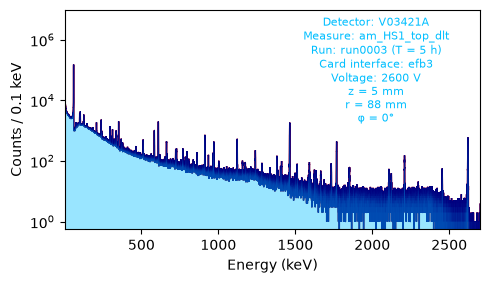

In [42]:
# ============================================================
# PLOT
# ============================================================
plt.figure(figsize=(5, 3))#, dpi = 300)


plt.stairs(
    counts_data,
    bins,
    color="red",
)
plt.stairs(
    counts_clean,
    bins,
    color="navy",
)
plt.stairs(
    counts_clean,
    bins,
    fill = True,
    alpha = 0.4,
    color="deepskyblue",
)

plt.annotate(
    annotation_measure,
    xy=(0.75, 0.97),
    xycoords="axes fraction",
    ha="center",
    va="top",
    multialignment="center",
    fontsize=8,
    zorder=8,
    color="deepskyblue",
)

# axvline non modifica i limiti verticali del grafico
#for energy in peaks.values():
#    plt.axvline(energy, color="red", linewidth=0.8)

#plt.axvline(2615, color="red", linewidth=0.8)

plt.yscale("log")
plt.ylim(0, 1e7)
plt.ylabel(f"Counts / {bins[1] - bins[0]:.1f} keV")
plt.xlabel("Energy (keV)")
plt.xlim(1, 2700)
plt.tight_layout()
plt.show()

In [43]:
print( Path("/global/u2/r/ritaferi/HADES_DATA")
    / "background_calibration_single_file"
    / version
    / campaign
    / detector)

/global/u2/r/ritaferi/HADES_DATA/background_calibration_single_file/v1.2.1/c1/V03421A


In [44]:
bkg_tak

'3'

In [45]:
bkg_run = f'run000{bkg_tak}'
folder = (
    Path("/global/u2/r/ritaferi/HADES_DATA")
    / "background_calibration_single_file"
    / version
    / campaign
    / detector
    / bkg_run
)

energy_path = folder / f"{detector}_bkg_{bkg_run}_e_cal.npy"

if not energy_path.is_file():
    raise FileNotFoundError(
        f"Energie calibrate non trovate:\n{energy_path}\n"
        f"File disponibili: {[p.name for p in folder.glob('*')]}"
    )

# mmap evita di caricare subito tutto il file in memoria.
energy_bkg_cal = np.load(
    energy_path,
    mmap_mode="r",
    allow_pickle=False,
)

print(f"File: {energy_path}")
print(f"Eventi: {energy_bkg_cal.size:,}")


File: /global/u2/r/ritaferi/HADES_DATA/background_calibration_single_file/v1.2.1/c1/V03421A/run0003/V03421A_bkg_run0003_e_cal.npy
Eventi: 6,021,455


In [46]:
import json
path = folder / f"{detector}_bkg_{bkg_run}_calibration.json"

with path.open(encoding="utf-8") as stream:
    calibration = json.load(stream)

# Dizionario completo.
#display(calibration);

# Coefficienti: E_cal = a0 + a1 * E_input + a2 * E_input**2
a0, a1, a2 = calibration["coefficients"]

print(f"a0 = {a0:.10g}")
print(f"a1 = {a1:.10g}")
print(f"a2 = {a2:.10g}")

a0 = 0.02434918937
a1 = 0.5430557594
a2 = 8.091018112e-08


In [47]:
bins

array([0.0000e+00, 1.0000e-01, 2.0000e-01, ..., 6.9998e+03, 6.9999e+03,
       7.0000e+03], shape=(70001,))

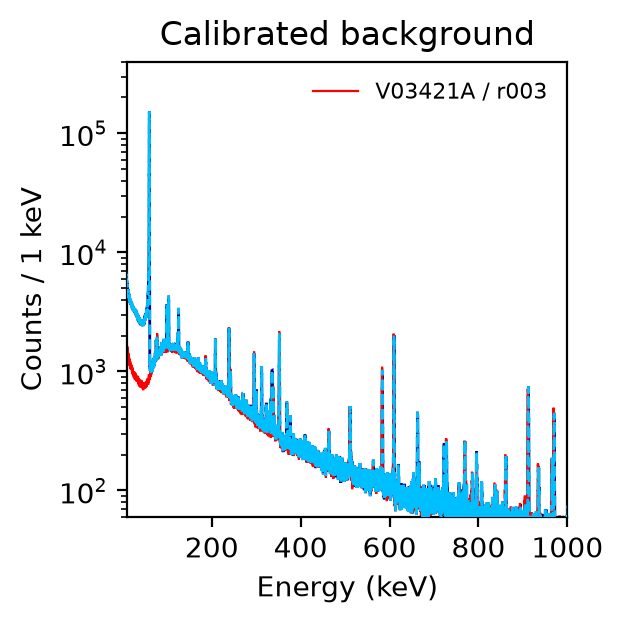

In [48]:

# ============================================================
# HISTOGRAM — 1 keV BINS
# ============================================================

#bins_bkg = np.linspace(0, 3500, 3501)

counts_bkg, _ = np.histogram(
    energy_bkg_cal,
    bins=bins,
)
bins
fig, ax = plt.subplots(
    figsize=(3,3),
    dpi=200,
    layout="constrained",
)

plt.stairs(
    counts_clean,
    bins,
    color="navy",
)
plt.stairs(
    counts_data,
    bins,
    color="deepskyblue",
    ls = '--',
    zorder = 10
)
ax.stairs(
    counts_bkg * alpha,
    bins,
    color="red",
    linewidth=0.8,
    label=f"{detector} / {run_tag}",
)



ax.set_yscale("log")
ax.set_ylim(bottom=0.5)
ax.set_xlim(10,1000)
ax.set_ylim(6e1, 4e5)

ax.set_xlabel("Energy (keV)")
ax.set_ylabel("Counts / 1 keV")
ax.set_title("Calibrated background")
ax.legend(frameon=False, fontsize=8)

plt.show()

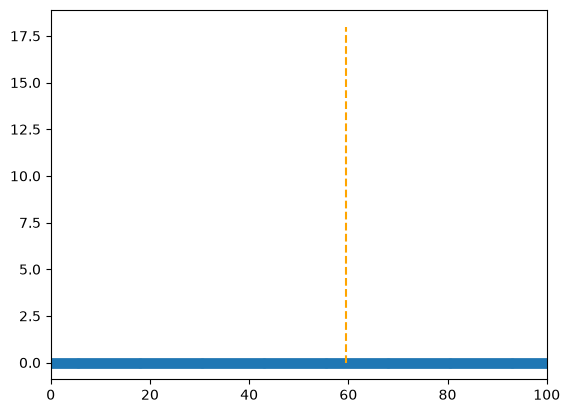

In [49]:
plt.scatter(bins[:-1], counts_data- counts_clean)
plt.xlim(0,100)
plt.vlines(59.5, 0, 18, ls = '--', color = 'orange')

# counting method

In [54]:
pattern = (
    "/global/cfs/cdirs/m2676/data/teststands/hades/"
    "prodenv/ref/v1.2.1/generated/par/hit/"
    f"{detector}/c1/am_HS1_lat_dlt/*.yaml"
)

files_par = sorted(glob.glob(pattern))

if not files_par:
    raise FileNotFoundError(f"Nessun file trovato: {pattern}")

print(f"File trovati: {len(files_par)}")

# Carica tutti i YAML: una voce per ogni file.
parameters_by_file = {}

for filename in files_par:
    with open(filename, encoding="utf-8") as stream:
        parameters_by_file[filename] = yaml.safe_load(stream)

    print(filename)

File trovati: 1
/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref/v1.2.1/generated/par/hit/V03421A/c1/am_HS1_lat_dlt/char_data-V03421A-am_HS1_lat_dlt-r001-20240324T201613Z-par_hit.yaml


In [55]:
par = parameters_by_file[files_par[0]]
print(par.keys())

dict_keys(['pars', 'results'])


In [57]:
def extract_sigma(E):
    a = par['results']['ecal']['cuspEmax_ctc_cal']["eres_quadratic"]["parameters"]["a"]

    b = par['results']['ecal']['cuspEmax_ctc_cal']["eres_quadratic"]["parameters"]["b"]
    
    c = par['results']['ecal']['cuspEmax_ctc_cal']["eres_quadratic"]["parameters"]["c"]
    
    return    (a+b*E+c*E**2)**(0.5)/2.355
    

In [58]:
extract_sigma(59.5)

0.2779058694554556

In [73]:
bc = (bins[1:] + bins[:-1])*0.5


e_left_low , e_left_high = (56.5, 57.5)
mask_left = (bc >= e_left_low) & (bc <= e_left_high )
e_right_low, e_rigth_high = (61.5, 62.5)
mask_right = (bc >= e_right_low) & (bc <= e_rigth_high )

sigma = extract_sigma(59.5)
p1 = 59.5
peak_range = (p1 - 3 * sigma, p1 + 3 * sigma )
mask_peak = (bc >= peak_range[0]) & (bc <= peak_range[1])

In [74]:
count_left = np.sum(counts_clean[mask_left])
count_right = np.sum(counts_clean[mask_right])
counts_peak = np.sum(counts_clean[mask_peak])

In [75]:

sigma_peak = np.sum(np.sqrt(counts_clean[mask_peak]))
sigma_left = np.sum(np.sqrt(counts_clean[mask_left])) / ((e_left_high - e_left_high) + (e_rigth_high - e_right_low))
sigma_right = np.sum(np.sqrt(counts_clean[mask_right])) / ((e_left_high - e_left_high) + (e_rigth_high - e_right_low))

# uncorrelated ucertainties
sigma_tot = sigma_peak - (sigma_left + sigma_right)

print(sigma_tot)

2848.76794459052


In [76]:
counts_net = counts_peak - (count_left + count_right )/((e_left_high - e_left_high) + (e_rigth_high - e_right_low))

print('left tail count', count_left)
print('right tail count', count_right)
print('peak count', counts_peak)
print('net peak count', counts_net, '+/-', int(sigma_tot),',', int(counts_net/counts_peak *100), '%')

left tail count 47938
right tail count 10343
peak count 1111332
net peak count 1053051.0 +/- 2848 , 94 %


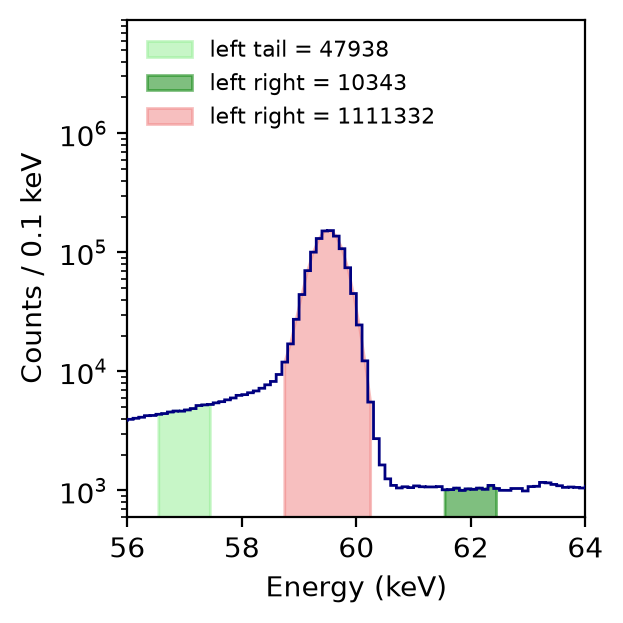

In [77]:

# ============================================================
# HISTOGRAM — 1 keV BINS
# ============================================================

#bins_bkg = np.linspace(0, 3500, 3501)

counts_bkg, _ = np.histogram(
    energy_bkg_cal,
    bins=bins,
)
bins
fig, ax = plt.subplots(
    figsize=(3,3),
    dpi=200,
    layout="constrained",
)

plt.stairs(
    counts_clean,
    bins,
    color="navy",
    zorder = 10
)

plt.fill_between(bc[mask_left] , counts_clean[mask_left] , color = 'lightgreen', alpha = 0.5,  label = f'left tail = {count_left} ')
plt.fill_between(bc[mask_right] , counts_clean[mask_right] , color = 'green',  alpha = 0.5, label = f'left right = {count_right} ')
plt.fill_between(bc[mask_peak] , counts_clean[mask_peak] , color = 'lightcoral', alpha = 0.5 , label = f'left right = {counts_peak} ')


ax.set_yscale("log")
ax.set_ylim(bottom=0.5)
ax.set_xlim(56,64)
ax.set_ylim(6e2, 9e6)

ax.set_xlabel("Energy (keV)")
ax.set_ylabel(f"Counts / {bins[1]-bins[0]:.1f} keV")
ax.legend(frameon=False, fontsize=8, loc = 'upper left')

plt.show()

In [68]:
bc = (bins[1:] + bins[:-1])*0.5


e_left_low , e_left_high = (94,96)
mask_left = (bc >= e_left_low) & (bc <= e_left_high )
e_right_low, e_rigth_high = (105, 107)
mask_right = (bc >= e_right_low) & (bc <= e_rigth_high )


p1 = 99
sigma = extract_sigma(p1)
peak_range1 = (p1 - 3 * sigma, p1 + 3 * sigma )
mask_peak1 = (bc >= peak_range1[0]) & (bc <= peak_range1[1])
p2 = 103
sigma = extract_sigma(p2)
peak_range2 = (p2 - 3 * sigma, p2 + 3 * sigma )
mask_peak2 = (bc >= peak_range2[0]) & (bc <= peak_range2[1])

In [69]:
count_left = np.sum(counts_clean[mask_left])
count_right = np.sum(counts_clean[mask_right])
counts_peak1 = np.sum(counts_clean[mask_peak1])
counts_peak2 = np.sum(counts_clean[mask_peak2])

In [70]:
counts_net1 = counts_peak1 - (count_left + count_right )/((e_left_high - e_left_high) + (e_rigth_high - e_right_low))
counts_net2 = counts_peak2 - (count_left + count_right )/((e_left_high - e_left_high) + (e_rigth_high - e_right_low))

print('left tail count', count_left)
print('right tail count', count_right)
print('peak count 99 keV', counts_peak1)
print('peak count 103 keV', counts_peak2)
print('net peak count 99 keV', counts_net1)
print('net peak count 103 keV', counts_net2) #, '+/-', int(sigma_tot),',', int(counts_net/counts_peak *100), '%')

left tail count 33223
right tail count 31361
peak count 99 keV 45596
peak count 103 keV 48952
net peak count 99 keV 13304.0
net peak count 103 keV 16660.0


In [71]:

sigma_peak1 = np.sum(np.sqrt(counts_clean[mask_peak1]))
sigma_peak2 = np.sum(np.sqrt(counts_clean[mask_peak2]))
sigma_left = np.sum(np.sqrt(counts_clean[mask_left])) / ((e_left_high - e_left_high) + (e_rigth_high - e_right_low))
sigma_right = np.sum(np.sqrt(counts_clean[mask_right])) / ((e_left_high - e_left_high) + (e_rigth_high - e_right_low))

# uncorrelated ucertainties
sigma_tot1 = sigma_peak1 - (sigma_left + sigma_right)
sigma_tot2 = sigma_peak2 - (sigma_left + sigma_right)
print(sigma_tot1)
print(sigma_tot2)

94.15747716325745
121.54222275828442


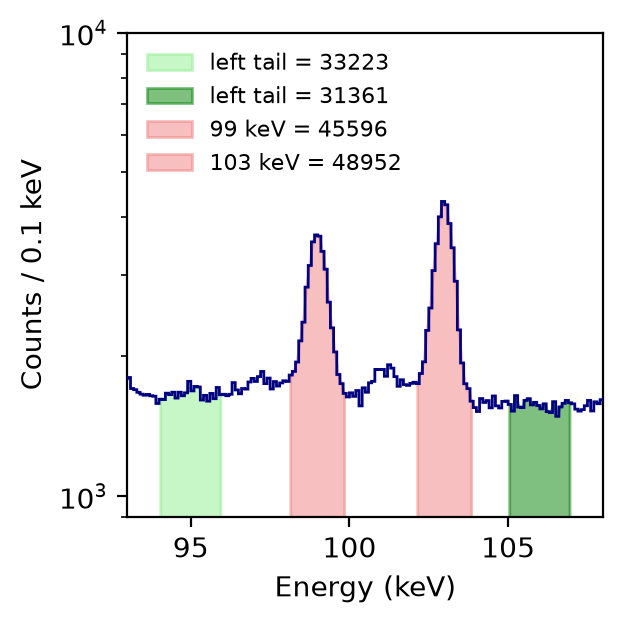

In [72]:

# ============================================================
# HISTOGRAM — 1 keV BINS
# ============================================================

#bins_bkg = np.linspace(0, 3500, 3501)

counts_bkg, _ = np.histogram(
    energy_bkg_cal,
    bins=bins,
)
bins
fig, ax = plt.subplots(
    figsize=(3,3),
    dpi=200,
    layout="constrained",
)

plt.stairs(
    counts_clean,
    bins,
    color="navy",
    zorder = 10
)

plt.fill_between(bc[mask_left] , counts_clean[mask_left] , color = 'lightgreen', alpha = 0.5,  label = f'left tail = {count_left} ')
plt.fill_between(bc[mask_right] , counts_clean[mask_right] , color = 'green',  alpha = 0.5, label = f'left tail = {count_right} ')
plt.fill_between(bc[mask_peak1] , counts_clean[mask_peak1] , color = 'lightcoral', alpha = 0.5 , label = f'99 keV = {counts_peak1} ')
plt.fill_between(bc[mask_peak2] , counts_clean[mask_peak2] , color = 'lightcoral', alpha = 0.5 , label = f'103 keV = {counts_peak2} ')


ax.set_yscale("log")
ax.set_ylim(bottom=0.5)
ax.set_xlim(93, 108)
ax.set_ylim(9e2, 1e4)

ax.set_xlabel("Energy (keV)")
ax.set_ylabel(f"Counts / {bins[1]-bins[0]:.1f} keV")
ax.legend(frameon=False, fontsize=8, loc = 'upper left')

plt.show()



# fit by Vale


# A/E

In [78]:
files = (
    f"/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref/"
    f"{version}/generated/tier/hit/{detector}/{campaign}/{measure}/*.lh5"
)
files_names = sorted(glob.glob(files))

In [79]:
hit = lh5.read(
            "hit",
            files_names,
        )

In [80]:
len(files_names)

90

In [81]:
blue = '#1A2A5B'
azzurro = '#07A9FF'
grigio = '#CCCCCC'

In [82]:
hit.keys()

dict_keys(['AoE_Classifier', 'AoE_Corrected', 'AoE_Double_Sided_Cut', 'AoE_High_Side_Cut', 'AoE_Low_Cut', 'LQ_Classifier', 'LQ_Cut', 'bl_pileup_cut', 'bl_pileup_cut_classifier', 'cuspEmax_cal', 'cuspEmax_ctc_cal', 'cuspEmax_noctc_cal', 'daqenergy_cal', 'dt_eff', 'is_discharge', 'is_downgoing_baseline', 'is_empty_candidate', 'is_highly_positive_polarity_candidate', 'is_low_cuspEmax', 'is_neg_energy', 'is_negative', 'is_negative_crosstalk_old', 'is_negative_polarity_candidate', 'is_noise_burst', 'is_not_noise_burst', 'is_positive_polarity_candidate', 'is_saturated', 'is_surface', 'is_upgoing_baseline', 'is_valid_0vbb_old', 'is_valid_baseline_old', 'is_valid_bl_slope', 'is_valid_bl_slope_classifier', 'is_valid_bl_slope_rms', 'is_valid_bl_slope_rms_classifier', 'is_valid_cal', 'is_valid_cuspEmax', 'is_valid_cuspEmax_classifier', 'is_valid_cuspEmin', 'is_valid_cuspEmin_classifier', 'is_valid_dteff', 'is_valid_dteff_old', 'is_valid_ediff', 'is_valid_efrac', 'is_valid_neg_current', 'is_valid_

In [83]:
max(hit['AoE_Classifier'])

np.float64(754385.4254480532)

In [84]:
aoe = np.asarray(hit["AoE_Corrected"].nda)
ene = np.asarray(hit["cuspEmax_ctc_cal"].nda)

is_discharge = np.asarray(
    hit["is_discharge"].nda,
    dtype=bool,
)

is_positive = np.asarray(
    hit["is_positive_polarity_candidate"].nda,
    dtype=bool,
)

mask = (~is_discharge) & is_positive

aoe = aoe[mask]
ene = ene[mask]

A/E di riferimento: 0.692347
Eventi nella finestra: 1,793,814


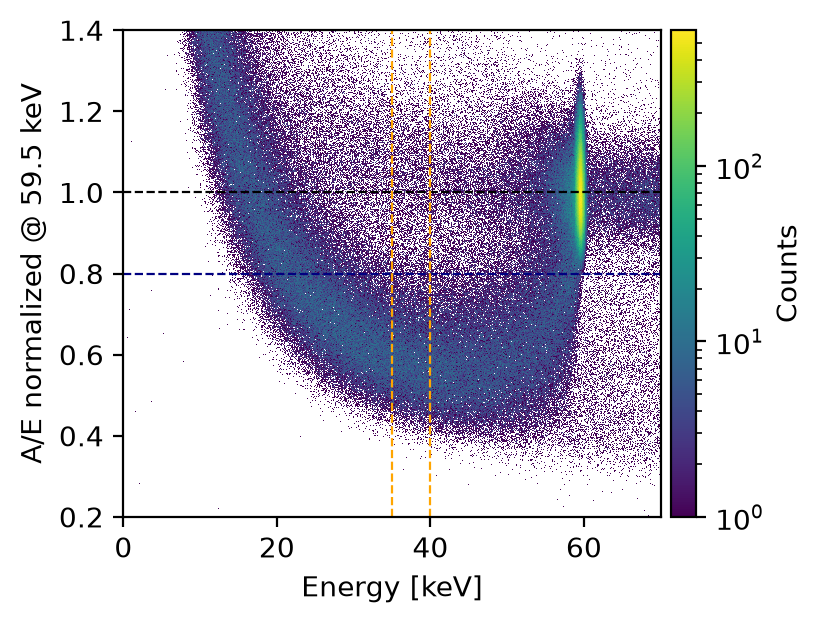

In [85]:
mask = np.isfinite(ene) & np.isfinite(aoe)


# Riferimento: eventi nella finestra 59–60 keV.
mask_60 = mask & (ene >= 59.5) & (ene < 60.5)

if not np.any(mask_60):
    raise ValueError("Nessun evento nella finestra 59–60 keV.")

aoe_ref = np.median(aoe[mask_60])

if not np.isfinite(aoe_ref) or aoe_ref <= 0:
    raise ValueError("Riferimento A/E non valido.")

aoe_norm = aoe / aoe_ref

print(f"A/E di riferimento: {aoe_ref:.6g}")
print(f"Eventi nella finestra: {mask_60.sum():,}")

cut = 0.80
emin, emax = 0, 70
aoemin, aoemax = 0.2, 1.4

bins_ene = np.linspace(emin, emax, 701)
bins_aoe = np.arange(aoemin, aoemax + 0.00022, 0.00022)

fig, ax = plt.subplots(
    figsize=(4, 3),
    dpi=200,
    layout="constrained",
)

cmap = plt.colormaps["viridis"].copy()
cmap.set_bad("white")

hist = ax.hist2d(
    ene[mask],
    aoe_norm[mask],
    bins=(bins_ene, bins_aoe),
    cmap=cmap,
    norm=LogNorm(),
    cmin=1,
)

ax.axhline(
    1,
    color="black",
    linestyle="--",
    linewidth=0.8,
)
ax.axhline(
    cut,
    color="navy",
    linestyle="--",
    linewidth=0.8,
    label='cut'
)

ax.set_xlim(emin, emax)
ax.set_ylim(aoemin, aoemax)

ax.set_xlabel("Energy [keV]")
ax.set_ylabel("A/E normalized @ 59.5 keV")

#plt.axvline(30, color = 'orange',  lw = 0.8)
#plt.axvline(45, color = 'orange',  lw = 0.8)

plt.axvline(35, color = 'orange', ls = '--', lw = 0.8)
plt.axvline(40, color = 'orange', ls = '--', lw = 0.8)

cbar = fig.colorbar(
    hist[3],
    ax=ax,
    orientation="vertical",
    pad=0.02,
    fraction=0.05,
)

cbar.set_label("Counts")


(0.0, 1.4)

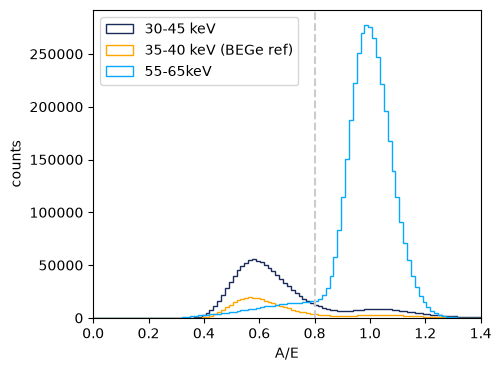

In [86]:
aoe_high = aoe_norm[(ene>55) & (ene <65)]
aoe_low = aoe_norm[(ene>30) & (ene <45)]
aoe_cenetr = aoe_norm[(ene>35) & (ene <40)]
min, max = (0, 1.4)
plt.figure(figsize = (5,4))
#plt.hist(aoe_norm, bins = 100, range = (min, max ), color = grigio, )
plt.hist(aoe_low,  bins =100 ,range = (min, max ), histtype = 'step',  color = blue, label = '30-45 keV')
#plt.hist(aoe_norm[(ene>30) & (ene <45)],  bins =100 ,range = (min, max ), histtype = 'step', ls = '--',  color = 'navy', label = '30-45 keV')
plt.hist(aoe_cenetr,  bins =100 ,range = (min, max ), histtype = 'step',  color = 'orange', label = '35-40 keV (BEGe ref)')
plt.hist(aoe_high,   bins = 100, range = (min, max ), histtype = 'step', color = azzurro, label = '55-65keV')
plt.axvline(cut, color = grigio, ls = '--')
#plt.yscale('log')
plt.xlabel('A/E')
plt.ylabel('counts')
plt.legend()
plt.xlim(0,1.4)

In [87]:


print(f'SP franction (30-45 keV) = {np.sum(aoe_low[(aoe_low>0.2) & (aoe_low<cut)]) / np.sum(aoe_high[(aoe_high>cut) & (aoe_high<1.25)])*100 :.0f} %')

print(f'SP franction (35-40 keV) = {np.sum(aoe_cenetr[(aoe_cenetr>0.2) & (aoe_cenetr<cut)]) / np.sum(aoe_high[(aoe_high>cut) & (aoe_high<1.25)])*100 :.0f} %')



SP franction (30-45 keV) = 15 %
SP franction (35-40 keV) = 5 %


(5.0, 80.0)

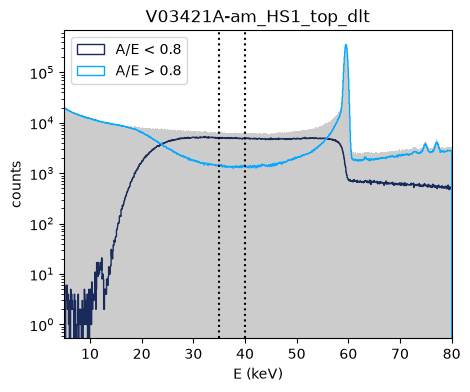

In [88]:
plt.figure(figsize = (5,4))
plt.hist(ene, bins = 1000, color  = grigio, range = (0, 80))
plt.hist(ene[aoe_norm<cut], bins = 1000, color = blue, histtype = 'step', range = (0, 80), label = f'A/E < {cut}')
plt.hist(ene[aoe_norm>cut], bins = 1000, color = azzurro, histtype = 'step',range = (0, 80), label = f'A/E > {cut}')
plt.legend()
plt.yscale('log')
plt.xlabel('E (keV)')
plt.ylabel('counts')
#plt.axvline(30, color = 'grey', ls = '--')
#plt.axvline(45, color = 'grey', ls = '--')
plt.axvline(35, color = 'black', ls = ':')
plt.axvline(40, color = 'black', ls = ':')
plt.title(f'{detector}-{measure}')
plt.xlim(5,80)

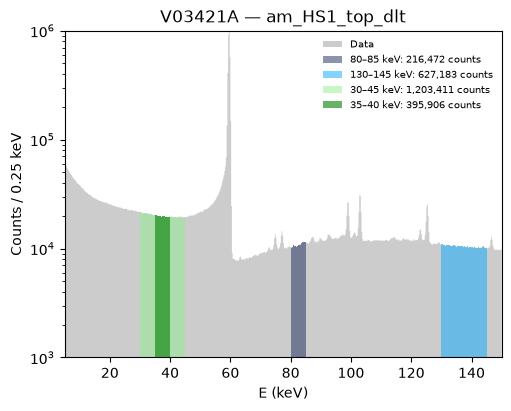

In [89]:
fig, ax = plt.subplots(
    figsize=(5, 4),
    #dpi=200,
    layout="constrained",
)

# Istogramma calcolato una sola volta.
c, be = np.histogram(
    ene,
    bins=600,
    range=(0, 150),
)

bc = (be[:-1] + be[1:]) / 2

ax.stairs(
    c,
    be,
    color=grigio,
    linewidth=0.8,
    
        fill=True,
    label="Data",
)

# Finestre selezionate usando i centri dei bin.
windows = [
    (80, 85, blue, 0.5),
    (130, 145, azzurro, 0.5),
    (30, 45, "lightgreen", 0.5),
    (35, 40, "green", 0.6),
]

for low, high, color, alpha in windows:
    mask = (bc >= low) & (bc < high)
    indices = np.flatnonzero(mask)

    if not indices.size:
        continue

    first = indices[0]
    last = indices[-1] + 1

    ax.stairs(
        c[first:last],
        be[first:last + 1],
        baseline=0,
        fill=True,
        color=color,
        alpha=alpha,
        label=f"{low}–{high} keV: {c[mask].sum():,.0f} counts",
    )

ax.set_yscale("log")
ax.set_xlim(5, 150)
ax.set_ylim(1e3, 1e6)

ax.set_xlabel("E (keV)")
ax.set_ylabel(f"Counts / {be[1] - be[0]:.2f} keV")
ax.set_title(f"{detector} — {measure}")

ax.legend(
    frameon=False,
    fontsize=7,
)

plt.show()

In [90]:
bc = (bins[1:]+bins[:-1]) * 0.5

In [91]:
SP_net = np.sum(counts_clean[(bc>30)&(bc<45)] - counts_clean[(bc>130)&(bc<145)])
p60_net = counts_net

In [92]:
Odlf = SP_net/p60_net

print(f'ratio for DLF = {Odlf}')

ratio for DLF = 0.1903269642211061


# DLF counting method

# Sims

In [93]:
detector

'V03421A'

In [94]:
detectors = [
    "V03421A",
    "V03422A",
    "V06643A",
    "V06659A",
    "V07298B",
    "V07302A",
    "V07302B",
    "V07647B",
    "V10437B",
    "V10447B",
    "V10784A",
    "V11924A",
    "V11925A",
    "V11947B",
    "V13044A",
    "V13049A",
    "V14618A",
    "V14654A",
    "V14673A",
]
from pathlib import Path

root = Path("/global/u2/r/ritaferi/HADES_DATA/hades-metadata")
folder = root / "hardware" / "cryostat"

missing_detectors = [
    det
    for det in detectors
    if not any(
        (folder / f"{det}{extension}").is_file()
        for extension in (".yaml", ".yml", ".json")
    )
]

print("Detector con metadati del criostato mancanti:")
print(missing_detectors)
        

Detector con metadati del criostato mancanti:
['V10784A', 'V13044A', 'V13049A', 'V14618A', 'V14654A']


In [95]:
configuration = db.hardware.configuration[detector]["c1"][measure]

In [96]:
import os

In [97]:
output_dir = "/global/u2/r/ritaferi/HADES_DATA"

In [98]:
run_key

'run0003'

In [99]:
from pathlib import Path

roots = [
    Path("/tmp/hades-metadata-ritaferi"),
    Path("/global/u2/r/ritaferi/HADES_DATA/hades-metadata"),
]

for root in roots:
    folder = root / "hardware" / "cryostat"
    print(detector)

    matches = [
        folder / f"{detector}{extension}"
        for extension in (".yaml", ".yml", ".json")
        if (folder / f"{detector}{extension}").is_file()
    ]

    print(f"\n{root}")
    print(
        "\n".join(str(path) for path in matches)
        if matches
        else "Cryostat metadata missing."
    )

V03421A

/tmp/hades-metadata-ritaferi
Cryostat metadata missing.
V03421A

/global/u2/r/ritaferi/HADES_DATA/hades-metadata
/global/u2/r/ritaferi/HADES_DATA/hades-metadata/hardware/cryostat/V03421A.yaml


In [100]:
#run = "run0001"
config_geom = deepcopy(configuration[run_key])

gdml_file = os.path.join(
    output_dir, f"{detector}_{measure}_{run_key}.gdml"
)

if os.path.isfile(gdml_file):
    reg = gdml.Reader(gdml_file).getRegistry()
    print(f"GDML già presente, caricato: {gdml_file}")
else:
    reg = pygeomhades.core.construct(config_geom)
    os.makedirs(output_dir, exist_ok=True)
    write_pygeom(reg, gdml_file)
    print(f"GDML creato: {gdml_file}")

Cloning git@github.com:legend-exp/hades-metadata in /tmp/hades-metadata-ritaferi...
Checking out the latest stable tag (v0.2.0)...
Translation to detector from for am_HS1 and r!=0 is uncertain. Proceed with caution.


GDML creato: /global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS1_top_dlt_run0003.gdml


In [101]:

def collect_global_placements(logical_volume, parent_matrix=None):
    """
    Percorre ricorsivamente il GDML e restituisce la trasformazione
    globale di ogni volume fisico.
    """
    if parent_matrix is None:
        parent_matrix = np.eye(4)

    placements = {}

    def walk(mother_lv, mother_matrix):
        for pv in mother_lv.daughterVolumes:
            local_matrix = physical_volume_matrix(pv)
            global_matrix = mother_matrix @ local_matrix

            logical_name = pv.logicalVolume.name

            placements.setdefault(logical_name, []).append({
                "physical_name": pv.name,
                "logical_volume": pv.logicalVolume,
                "matrix": global_matrix,
            })

            walk(pv.logicalVolume, global_matrix)

    walk(logical_volume, parent_matrix)

    return placements


def find_germanium_detector(reg):
    candidates = []

    for name, lv in reg.logicalVolumeDict.items():
        material_name = getattr(lv.material, "name", str(lv.material))

        if "Germanium" in material_name:
            candidates.append(name)

    if len(candidates) == 0:
        raise ValueError("Nessun detector al germanio trovato")

    if len(candidates) > 1:
        print("Detector al germanio trovati:", candidates)

    return candidates[0]



def find_source(reg):
    candidates = []

    for name, lv in reg.logicalVolumeDict.items():
        material_name = getattr(lv.material, "name", str(lv.material))

        if "Source" in material_name:
            candidates.append(name)

    if len(candidates) == 0:
        raise ValueError("Nessuna sorgente trovate")

    if len(candidates) > 1:
        print("Sorgente trovata:", candidates)

    return candidates[0]

def tubs_profile(solid):
    """Profilo r-z di un cilindro Tubs."""

    rmin = float(solid.evaluateParameterWithUnits("pRMin"))
    rmax = float(solid.evaluateParameterWithUnits("pRMax"))
    dz = float(solid.evaluateParameterWithUnits("pDz"))

    # pDz è la lunghezza totale lungo z
    zmin = -dz / 2
    zmax = dz / 2

    r = np.array([
        rmin,
        rmax,
        rmax,
        rmin,
        rmin
    ])

    z = np.array([
        zmin,
        zmin,
        zmax,
        zmax,
        zmin
    ])

    return r, z

def box_profile(solid):
    """Profilo nel piano locale x-z di un Box."""

    size_x = float(solid.evaluateParameterWithUnits("pX"))
    size_z = float(solid.evaluateParameterWithUnits("pZ"))

    xmin = -size_x / 2
    xmax = size_x / 2
    zmin = -size_z / 2
    zmax = size_z / 2

    r = np.array([
        xmin,
        xmax,
        xmax,
        xmin,
        xmin
    ])

    z = np.array([
        zmin,
        zmin,
        zmax,
        zmax,
        zmin
    ])

    return r, z

def transform_profile(r, z, matrix):
    """
    Trasforma un profilo locale (r, z) nelle coordinate globali.

    Parameters
    ----------
    r : array-like
        Coordinate radiali locali.
    z : array-like
        Coordinate verticali locali.
    matrix : array-like, shape (4, 4)
        Matrice omogenea contenente rotazione e traslazione globali.

    Returns
    -------
    radius : ndarray
        Distanza globale dall'asse z.
    height : ndarray
        Coordinata z globale.
    """

    r = np.asarray(r, dtype=float)
    z = np.asarray(z, dtype=float)

    # Punti omogenei locali: (x=r, y=0, z, 1)
    points = np.column_stack([
        r,
        np.zeros_like(r),
        z,
        np.ones_like(r)
    ])

    # Trasformazione nelle coordinate globali
    transformed = (matrix @ points.T).T

    x_global = transformed[:, 0]
    y_global = transformed[:, 1]
    z_global = transformed[:, 2]

    radius = np.sqrt(x_global**2 + y_global**2)
    height = z_global
    
    return radius, height

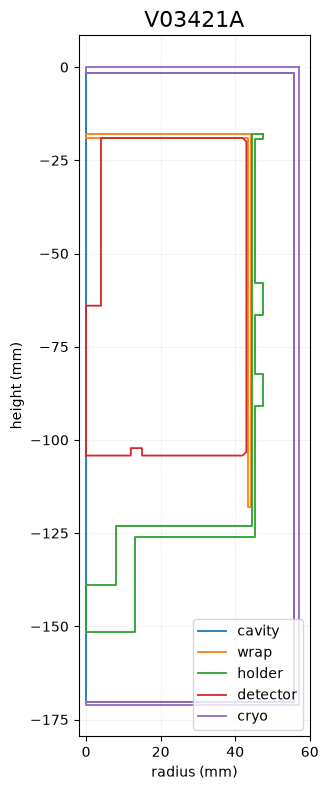

In [102]:
def generic_polycone_profile(solid):
    r = np.asarray(
        solid.evaluateParameterWithUnits("pR"),
        dtype=float
    )
    z = np.asarray(
        solid.evaluateParameterWithUnits("pZ"),
        dtype=float
    )

    return np.append(r, r[0]), np.append(z, z[0])


def polycone_profile(solid):
    z = np.asarray(
        solid.evaluateParameterWithUnits("pZpl"),
        dtype=float
    )
    rmin = np.asarray(
        solid.evaluateParameterWithUnits("pRMin"),
        dtype=float
    )
    rmax = np.asarray(
        solid.evaluateParameterWithUnits("pRMax"),
        dtype=float
    )

    r = np.concatenate([rmax, rmin[::-1], [rmax[0]]])
    z = np.concatenate([z, z[::-1], [z[0]]])

    return r, z

    
def get_profile(solid):
    solid_type = str(solid.type).lower()

    if "genericpolycone" in solid_type:
        return generic_polycone_profile(solid)

    if "polycone" in solid_type:
        return polycone_profile(solid)

    if "tubs" in solid_type or "tube" in solid_type:
        return tubs_profile(solid)

    if "box" in solid_type:
        return box_profile(solid)

    raise TypeError(
        f"Solido {solid.name} di tipo {solid.type} non supportato"
    )

def evaluate_vector(vector):
    """Converte Position o Rotation di pyg4ometry in array numerico."""
    return np.asarray(vector.eval(), dtype=float)


def physical_volume_matrix(pv):
    """Matrice omogenea della trasformazione del PhysicalVolume."""
    position = evaluate_vector(pv.position)
    rotation = evaluate_vector(pv.rotation)

    rotation_matrix = np.linalg.inv(
        pg4.transformation.tbxyz2matrix(rotation)
    )

    matrix = np.eye(4)
    matrix[:3, :3] = rotation_matrix
    matrix[:3, 3] = position

    return matrix

placements = collect_global_placements(reg.getWorldVolume())

detector_name = find_germanium_detector(reg)

components = {
    "cavity_lv": {
        "label": "cavity",
        "color": "tab:blue"
    },
    "Wrap": {
        "label": "wrap",
        "color": "tab:orange"
    },
    "Holder": {
        "label": "holder",
        "color": "tab:green"
    },
    detector_name: {
        "label": "detector",
        "color": "tab:red"
    },
    "Cryostat": {
        "label": "cryo",
        "color": "tab:purple"
    },
}

fig, ax = plt.subplots(figsize=(4,8))

for logical_name, style in components.items():

    if logical_name not in placements:
        print(f"Volume non trovato: {logical_name}")
        continue

    # Se esistono più copie, le disegna tutte
    for index, placement in enumerate(placements[logical_name]):

        lv = placement["logical_volume"]
        matrix = placement["matrix"]

        try:
            r_local, z_local = get_profile(lv.solid)
        except TypeError as error:
            print(error)
            continue

        radius, height = transform_profile(
            r_local,
            z_local,
            matrix
        )

        # Una sola voce in legenda per componente
        label = style["label"] if index == 0 else None

        ax.plot(
            radius,
            height,
            color=style["color"],
            linewidth=1.3,
            label=label
        )

ax.set_title(detector_name, fontsize=16)
ax.set_xlabel("radius (mm)")
ax.set_ylabel("height (mm)")

ax.set_xlim(left=-2)
ax.set_aspect("equal", adjustable="box")

ax.grid(alpha=0.15)
ax.legend(loc = 'lower right')

plt.tight_layout()
plt.show()

In [103]:
import os

In [221]:
run_key

'run0003'

In [104]:
peaks = {
    "gamma_59p9keV": 59.9,
    #"gamma_99keV": 99.0,
    #"gamma_103keV": 103.0,
    #"gamma_123p1keV": 123.1,
    #"gamma_125p3keV": 125.3,
    #"gamma_208p1keV": 208.1,
    #"gamma_335p4keV": 335.4,
    #"gamma_662p4keV": 662.4,
}

N_sim = 100000000


force_rerun = False

os.makedirs(output_dir, exist_ok=True)
simulation_files = {}

for name, energy_keV in peaks.items():

    output_file = os.path.join(
        output_dir,
        f"{detector}_{measure}_{run_key}_{name}.lh5"
    )

    if os.path.isfile(output_file) and not force_rerun:
        simulation_files[name] = output_file
        print(f"✅ {name}: uso il file esistente → {output_file}")
        continue

    macro = [
        "/RMG/Manager/Logging/LogLevel summary",
        "/RMG/Processes/HadronicPhysics Shielding",
    
        f"/RMG/Geometry/RegisterDetector Germanium {detector} 1",
    
        "/RMG/Output/NtupleUseVolumeName true",
        "/RMG/Output/NtuplePerDetector false",
    
        "/run/initialize",
    
        "/RMG/Generator/Confine Volume",
        "/RMG/Generator/Confinement/Physical/AddVolume Source_PV",
    
        "/RMG/Generator/Select GPS",
        "/gps/particle gamma",
        "/gps/number 1",
        "/gps/ene/type Mono",
        f"/gps/ene/mono {energy_keV} keV",
        "/gps/ang/type iso",
    
        f"/run/beamOn {int(N_sim)}",
    ]
    print(f"▶ {name}: avvio simulazione → {output_file}")

    try:
        remage_run(
            macros=macro,
            gdml_files=gdml_file,
            output=output_file,
            overwrite_output=True,
        )
        simulation_files[name] = output_file
        print(f"✅ {name}: simulazione completata")

    except Exception as e:
        print(f"❌ {name}: {e}")

print("\nFile disponibili:", simulation_files)



✅ gamma_59p9keV: uso il file esistente → /global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS1_top_dlt_run0003_gamma_59p9keV.lh5

File disponibili: {'gamma_59p9keV': '/global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS1_top_dlt_run0003_gamma_59p9keV.lh5'}


In [105]:
N_sim_by_peak = {}
energies = ["gamma_59p9keV", "gamma_99keV","gamma_103keV",
    "gamma_123p1keV",
    "gamma_125p3keV",
    "gamma_208p1keV",
    "gamma_335p4keV",
    "gamma_662p4keV"]

for name in energies:
    filename = os.path.join(
        output_dir, f"{detector}_{measure}_{run_key}_{name}.lh5"
    )

    obj = lh5.read("number_of_simulated_events", filename)

    # Compatibilità con versioni che restituiscono una tupla
    if isinstance(obj, tuple):
        obj = obj[0]

    N_sim_by_peak[name] = int(obj.value)
    print(f"{name}: {N_sim_by_peak[name]:,} eventi simulati")

gamma_59p9keV: 10,000,000 eventi simulati
gamma_99keV: 1,000,000 eventi simulati
gamma_103keV: 1,000,000 eventi simulati
gamma_123p1keV: 1,000,000 eventi simulati
gamma_125p3keV: 1,000,000 eventi simulati
gamma_208p1keV: 1,000,000 eventi simulati
gamma_335p4keV: 1,000,000 eventi simulati
gamma_662p4keV: 1,000,000 eventi simulati


In [106]:
run_key

'run0003'

In [107]:
import awkward as ak

PATH: /global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS1_top_dlt_run0003_gamma_59p9keV.lh5 | esiste: True


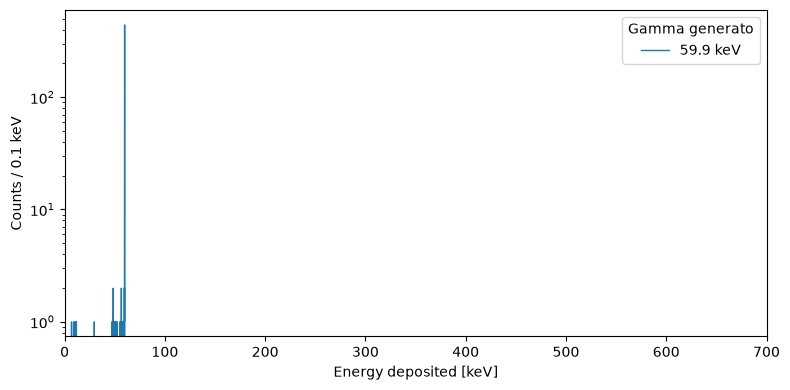

In [108]:
fig, ax = plt.subplots(figsize=(8, 4))
has_counts = False

for i, (name, energy_keV) in enumerate(peaks.items()):

    filename = simulation_files.get(
        name,
        os.path.join(
            output_dir,
            f"{detector}_{measure}_{run_key}_{name}.lh5"
        )
    )

    print("PATH:", filename, "| esiste:", os.path.isfile(filename))

    try:
        data = lh5.read_as("stp/germanium", filename, "ak")
        energy = ak.to_numpy(ak.sum(data.edep, axis=-1))
        energy = energy[energy > 0]

        counts, _ = np.histogram(energy, bins=bins)

        if counts.sum() == 0:
            print(f"{name}: nessun deposito nell'intervallo del grafico")
            continue

        ax.stairs(
            counts,
            bins,
            #color=colors[i % len(colors)],
            label=f"{energy_keV:g} keV"
        )
        has_counts = True

    except Exception:
        print(f"Errore durante la lettura o il grafico di {name}:")
        traceback.print_exc()

if has_counts:
    ax.set_xlabel("Energy deposited [keV]")
    ax.set_ylabel(f"Counts / {bins[1]-bins[0]:.1f} keV")
    ax.set_xlim(emin, 700)
    ax.set_yscale("log")
    ax.legend(title="Gamma generato")
    fig.tight_layout()
    plt.show()
else:
    plt.close(fig)
    print("Nessun conteggio da mostrare")

In [117]:
BR = {
    "gamma_59p9keV":  0.359,
    "gamma_99keV":    2.03e-3,
    "gamma_103keV":   1.95e-3,
    "gamma_123p1keV": 1.00e-5,
    "gamma_125p3keV": 4.08e-5,
    "gamma_208p1keV": 7.91e-6,
    "gamma_335p4keV": 4.96e-6,
    "gamma_662p4keV": 3.6e-8,
}


In [118]:
bins[1]-bins[0]

np.float64(0.1)

gamma_59p9keV: N_sim = 10,000,000, peso = 2778.66
gamma_99keV: N_sim = 1,000,000, peso = 157.122
gamma_103keV: N_sim = 1,000,000, peso = 150.93
gamma_123p1keV: N_sim = 1,000,000, peso = 0.774
gamma_125p3keV: N_sim = 1,000,000, peso = 3.15792
gamma_208p1keV: N_sim = 1,000,000, peso = 0.612234
gamma_335p4keV: N_sim = 1,000,000, peso = 0.383904
gamma_662p4keV: N_sim = 1,000,000, peso = 0.0027864


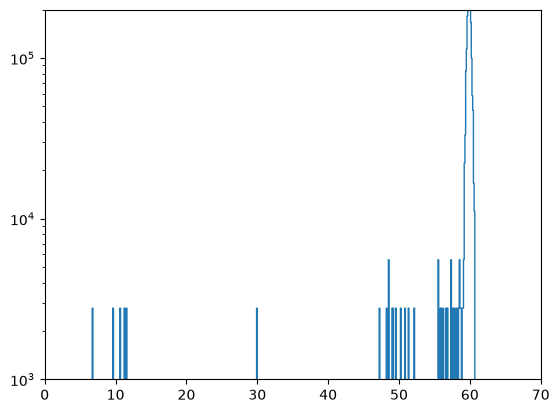

In [124]:

activity = 4.3e6 # Bq: valore nominale comune alla misura

counts_theory = np.zeros(len(bins) - 1)
counts_smeared = np.zeros(len(bins) - 1)

for name, br in BR.items():

    filename = os.path.join(
        output_dir, f"{detector}_{measure}_{run_key}_{name}.lh5"
    )

    # Gli errori di lettura vengono mostrati, evitando somme incomplete
    data = lh5.read_as("stp/germanium", filename, "ak")
    energy = ak.to_numpy(ak.sum(data.edep, axis=-1))
    energy = energy[energy > 0]

    if len(energy) == 0:
        print(f"{name}: nessun deposito positivo di energia")
        continue

    sigma = extract_sigma(energy)
    energy_smeared = ak.to_numpy(
        reboost.math.stats.gaussian_sample(energy, sigma=sigma)
    )

    N_sim = N_sim_by_peak[name]
    if N_sim <= 0:
        raise ValueError(f"{name}: N_sim deve essere positivo")

    # BR applicato una sola volta, nel peso
    peso = activity * time_data * br / N_sim
    weights = np.full(len(energy), peso)

    counts_iso, _ = np.histogram(
        energy, bins=bins, weights=weights
    )
    counts_iso_smeared, _ = np.histogram(
        energy_smeared, bins=bins, weights=weights
    )

    plt.stairs(counts_iso_smeared, bins , label = f'{name}')
    plt.xlim(0,70)
    plt.ylim(1e3, 2e5)
    plt.yscale('log')

    counts_theory += counts_iso
    counts_smeared += counts_iso_smeared

    print(f"{name}: N_sim = {N_sim:,}, peso = {peso:.6g}")

counts_MC = counts_smeared

In [125]:
folder = (
    Path("/global/u2/r/ritaferi/HADES_DATA")
    / "background_calibration_single_file"
    / version
    / campaign
    / detector
)

for file in sorted(folder.glob("*/*_e_cal.npy")):
    print(file.parent.name, "→", file.name)

run0003 → V03421A_bkg_run0003_e_cal.npy


In [126]:
bkg_run = 'run0003'
folder = (
    Path("/global/u2/r/ritaferi/HADES_DATA")
    / "background_calibration_single_file"
    / version
    / campaign
    / detector
    / bkg_run
)

energy_path = folder / f"{detector}_bkg_{bkg_run}_e_cal.npy"

if not energy_path.is_file():
    raise FileNotFoundError(
        f"Energie calibrate non trovate:\n{energy_path}\n"
        f"File disponibili: {[p.name for p in folder.glob('*')]}"
    )

# mmap evita di caricare subito tutto il file in memoria.
energy_bkg_cal = np.load(
    energy_path,
    mmap_mode="r",
    allow_pickle=False,
)

print(f"File: {energy_path}")
print(f"Eventi: {energy_bkg_cal.size:,}")

print(f"Detector: {detector} — {run_tag}")
print(f"Eventi: {energy_bkg_cal.size:,}")
#print("Prime energie (keV):", energy_bkg_cal[:10])

File: /global/u2/r/ritaferi/HADES_DATA/background_calibration_single_file/v1.2.1/c1/V03421A/run0003/V03421A_bkg_run0003_e_cal.npy
Eventi: 6,021,455
Detector: V03421A — r003
Eventi: 6,021,455


In [127]:
counts_bkg, _ = np.histogram(energy_bkg_cal, bins, weights = np.full(len(energy_bkg_cal),time_data / time_bkg))

In [ ]:
#plt.stairs(counts_MC, bins, label = 'MC')
#plt.stairs(counts_bkg, bins, label = 'bkg')
plt.stairs(counts_MC + counts_bkg, bins, label = 'MC + bkg')
plt.stairs(counts_data, bins, label = 'data')
plt.legend()
plt.xlim(98,105)
plt.ylim(1e3,1e4)
plt.yscale('log')